### Customer Segmentation Analysis
##### Objective: Apply clustering algorithms to segment an e-commerce company's customer base into distinct groups based on purchasing behavior, enabling targeted marketing strategies.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Load data
data = pd.read_excel('ecommerce_rfm_dataset.xlsx')

In [3]:
# Data Inspection
print(f"Shape: {data.shape}")
print(f"\nMissing values:\n{data.isnull().sum()}")
print(f"\nData types:\n{data.dtypes}")

Shape: (22000, 20)

Missing values:
OrderID                0
CustomerID             0
CustomerName         731
Gender                 0
AgeGroup               0
Region                 0
Segment                0
PreferredChannel       0
SignupDate             0
ProductName            0
Category               0
OrderDate              0
Channel                0
Quantity               0
UnitPrice              0
GrossAmount            0
DiscountPct         7507
DiscountAmount         0
NetAmount              0
PaymentMethod          0
dtype: int64

Data types:
OrderID                     object
CustomerID                   int64
CustomerName                object
Gender                      object
AgeGroup                    object
Region                      object
Segment                     object
PreferredChannel            object
SignupDate          datetime64[ns]
ProductName                 object
Category                    object
OrderDate           datetime64[ns]
Channel           

In [4]:
data.head()

,OrderID,CustomerID,CustomerName,Gender,AgeGroup,Region,Segment,PreferredChannel,SignupDate,ProductName,Category,OrderDate,Channel,Quantity,UnitPrice,GrossAmount,DiscountPct,DiscountAmount,NetAmount,PaymentMethod
0,O000001,566,Customer 0566,M,25-34,South West,Consumer,Mobile App,2022-06-01,Hoodie,Fashion,2025-10-12,Mobile App,1,36236.31,36236.31,NaN,0.00,36236.31,Wallet
1,O000002,1456,Customer 1456,M,25-34,North West,Corporate,Website,2023-11-05,Power Bank,Electronics,2025-08-23,Mobile App,1,23720.23,23720.23,NaN,0.00,23720.23,Wallet
2,O000003,549,Customer 0549,male,25-34,South South,Consumer,Mobile App,2023-01-03,Electric Kettle,Home Appliances,2025-04-25,Website,1,35457.00,35457.00,5.0,1772.85,33684.15,Wallet
3,O000004,1426,Customer 1426,male,35-44,South South,Consumer,Social Commerce,2023-10-06,Smart Watch,Electronics,2025-03-09,Social Commerce,4,58012.03,232048.12,NaN,0.00,232048.12,Card
4,O000005,766,Customer 0766,Male,55+,South West,Corporate,Marketplace,2025-05-11,Skincare Set,Beauty,2025-06-09,Marketplace,3,49582.27,148746.81,10.0,14874.68,133872.13,Bank Transfer


In [5]:
# Check CustomerName column entries
data['CustomerName'].value_counts()

CustomerName
UNKNOWN          270
Customer 0379     49
Customer 0611     45
Customer 1852     44
Customer 1589     42
                ... 
Customer 1609      1
Customer 0047      1
Customer 1281      1
Customer 0194      1
Customer 0836      1
Name: count, Length: 1906, dtype: int64

In [6]:
mask = data['CustomerName'] == 'UNKNOWN'

In [7]:
data[mask]

,OrderID,CustomerID,CustomerName,Gender,AgeGroup,Region,Segment,PreferredChannel,SignupDate,ProductName,Category,OrderDate,Channel,Quantity,UnitPrice,GrossAmount,DiscountPct,DiscountAmount,NetAmount,PaymentMethod
12,O000013,547,UNKNOWN,Male,18-24,North Central,Consumer,Marketplace,2022-01-15,Power Bank,Electronics,2025-08-28,Marketplace,4,24088.24,96352.96,NaN,0.00,96352.96,Card
21,O000022,413,UNKNOWN,male,25-34,South South,Small Business,Website,2023-10-08,Power Bank,Electronics,2025-02-22,Website,2,23755.77,47511.54,NaN,0.00,47511.54,Wallet
93,O000094,413,UNKNOWN,Female,25-34,South South,Small Business,Website,2023-10-08,Power Bank,Electronics,2025-07-06,Website,6,23571.32,141427.92,NaN,0.00,141427.92,Wallet
131,O000132,1411,UNKNOWN,Female,25-34,South West,Consumer,Website,2023-11-29,LED TV,Home Appliances,2025-10-06,Website,2,293454.25,586908.50,5.0,29345.42,557563.08,Bank Transfer
216,O000217,1411,UNKNOWN,M,25-34,South West,Consumer,Website,2023-11-29,Phone Charger,Electronics,2025-02-07,Marketplace,3,8836.95,26510.85,NaN,0.00,26510.85,Card
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10461,O010462,545,UNKNOWN,male,18-24,South East,Consumer,Mobile App,2024-01-15,Bluetooth Speaker,Electronics,2024-01-25,Mobile App,1,43313.36,43313.36,NaN,0.00,43313.36,USSD
10472,O010473,413,UNKNOWN,Female,25-34,South South,Small Business,Website,2023-10-08,Hair Care Bundle,Beauty,2025-07-14,Website,1,33929.70,33929.70,NaN,0.00,33929.70,Bank Transfer
10493,O010494,406,UNKNOWN,Male,35-44,South West,Small Business,Website,2024-11-12,Desk Lamp,Office,2025-05-13,Mobile App,3,22011.22,66033.66,5.0,3301.68,62731.98,Cash on Delivery
10504,O010505,859,UNKNOWN,Male,18-24,South West,Corporate,Mobile App,2025-10-06,Backpack,Fashion,2025-09-20,Mobile App,2,38821.35,77642.70,15.0,11646.40,65996.30,USSD


In [8]:
# Force 'Unknown' to NaN
import numpy as np
data['CustomerName'] = data['CustomerName'].replace("UNKNOWN", np.nan)
print(data['CustomerName'].isna().sum())

1001


In [9]:
# Fill CustomerName column
data['CustomerName'] = data['CustomerName'].fillna(
    "Customer " + data['CustomerID'].astype(str).str.zfill(4)
)
print(data['CustomerName'].isna().sum())

0


In [10]:
# Fit the data inconsistencies in Gender
print(f"Before: {data['Gender'].unique()}")

data['Gender'] = data['Gender'].replace(["M", "Male", "male"], "Male")

data['Gender'] = data['Gender'].replace(["F", "Female"], "Female")

print(f"After: {data['Gender'].unique()}")

Before: ['M' 'male' 'Male' 'Female' 'F']
After: ['Male' 'Female']


In [11]:
print(data[['DiscountPct', 'DiscountAmount']].head())
print(f"Missing values: {data['DiscountPct'].isna().sum()}")

   DiscountPct  DiscountAmount
0          NaN            0.00
1          NaN            0.00
2          5.0         1772.85
3          NaN            0.00
4         10.0        14874.68
Missing values: 7507


In [12]:
mask1 = data['DiscountAmount'] == 0
data[mask1]

,OrderID,CustomerID,CustomerName,Gender,AgeGroup,Region,Segment,PreferredChannel,SignupDate,ProductName,Category,OrderDate,Channel,Quantity,UnitPrice,GrossAmount,DiscountPct,DiscountAmount,NetAmount,PaymentMethod
0,O000001,566,Customer 0566,Male,25-34,South West,Consumer,Mobile App,2022-06-01,Hoodie,Fashion,2025-10-12,Mobile App,1,36236.31,36236.31,NaN,0.0,36236.31,Wallet
1,O000002,1456,Customer 1456,Male,25-34,North West,Corporate,Website,2023-11-05,Power Bank,Electronics,2025-08-23,Mobile App,1,23720.23,23720.23,NaN,0.0,23720.23,Wallet
3,O000004,1426,Customer 1426,Male,35-44,South South,Consumer,Social Commerce,2023-10-06,Smart Watch,Electronics,2025-03-09,Social Commerce,4,58012.03,232048.12,NaN,0.0,232048.12,Card
5,O000006,1542,Customer 1542,Female,45-54,South South,Consumer,Website,2025-10-08,Phone Charger,Electronics,2025-09-17,Website,3,8858.67,26576.01,NaN,0.0,26576.01,Card
6,O000007,293,Customer 0293,Male,25-34,South South,Corporate,Website,2024-09-10,Skincare Set,Beauty,2024-04-07,Website,10,45994.63,459946.30,NaN,0.0,459946.30,Card
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21989,O021990,1288,Customer 1288,Male,45-54,North Central,Consumer,Marketplace,2023-10-22,Desk Lamp,Office,2024-03-25,Marketplace,2,22478.77,44957.54,NaN,0.0,44957.54,USSD
21990,O021991,1018,Customer 1018,Male,25-34,North West,Consumer,Marketplace,2025-01-02,Wireless Earbuds,Electronics,2025-06-27,Marketplace,2,35223.37,70446.74,NaN,0.0,70446.74,Wallet
21994,O021995,1000,Customer 1000,Male,45-54,South South,Consumer,Marketplace,2024-05-08,Hair Care Bundle,Beauty,2025-12-09,Marketplace,3,33447.94,100343.82,NaN,0.0,100343.82,Bank Transfer
21995,O021996,727,Customer 0727,Male,18-24,South West,Consumer,Mobile App,2024-04-26,Bluetooth Speaker,Electronics,2025-06-13,Mobile App,3,43019.02,129057.06,NaN,0.0,129057.06,Wallet


In [13]:
# Fill blank rows in DiscountPct with 0
print(f"Before - missing values: {data['DiscountPct'].isna().sum()}")

data['DiscountPct'] = data['DiscountPct'].fillna(0)

print(f"After - missing values: {data['DiscountPct'].isna().sum()}")

Before - missing values: 7507
After - missing values: 0


In [14]:
data.head(3)

,OrderID,CustomerID,CustomerName,Gender,AgeGroup,Region,Segment,PreferredChannel,SignupDate,ProductName,Category,OrderDate,Channel,Quantity,UnitPrice,GrossAmount,DiscountPct,DiscountAmount,NetAmount,PaymentMethod
0,O000001,566,Customer 0566,Male,25-34,South West,Consumer,Mobile App,2022-06-01,Hoodie,Fashion,2025-10-12,Mobile App,1,36236.31,36236.31,0.0,0.00,36236.31,Wallet
1,O000002,1456,Customer 1456,Male,25-34,North West,Corporate,Website,2023-11-05,Power Bank,Electronics,2025-08-23,Mobile App,1,23720.23,23720.23,0.0,0.00,23720.23,Wallet
2,O000003,549,Customer 0549,Male,25-34,South South,Consumer,Mobile App,2023-01-03,Electric Kettle,Home Appliances,2025-04-25,Website,1,35457.00,35457.00,5.0,1772.85,33684.15,Wallet


In [15]:
# Descriptive Statistics
customer_stats = data.groupby('CustomerName').agg(
    AvgPurchaseValue=('NetAmount', 'mean'),
    PurchaseFrequency=('OrderID', 'count'),
    CLV=('NetAmount', 'sum')
).reset_index()

customer_stats.describe()

,AvgPurchaseValue,PurchaseFrequency,CLV
count,1994.000000,1994.000000,1.994000e+03
mean,104000.059153,11.033099,1.173464e+06
std,54460.639579,8.394435,1.072285e+06
min,7419.420000,1.000000,7.419420e+03
25%,71121.926437,5.000000,4.374208e+05
50%,94223.776629,9.000000,8.543595e+05
75%,122745.405000,14.000000,1.513920e+06
max,780417.918000,49.000000,7.372527e+06


In [16]:
# Recency
date = data['OrderDate'].max() + pd.Timedelta(days=1)

recency = data.groupby('CustomerName')['OrderDate'].max().apply(
    lambda x: (date - x).days
)

In [17]:
# Frequency
frequency = data.groupby('CustomerName')['OrderID'].count()

In [18]:
# Monetary
monetary = data.groupby('CustomerName')['NetAmount'].sum()

In [19]:
# Combine all into one RFM table
rfm = pd.DataFrame({
    'Recency': recency,
    'Frequency': frequency,
    'Monetary': monetary
})

rfm.head()

,Recency,Frequency,Monetary
CustomerName,,,
Customer 0001,102,14,1300528.40
Customer 0002,660,2,308193.76
Customer 0003,53,9,1107178.60
Customer 0004,38,13,974845.03
Customer 0005,115,5,643058.04


In [20]:
from sklearn.preprocessing import StandardScaler

# Select only the features to scale - not CustomerName
features = rfm[['Recency', 'Frequency', 'Monetary']]

scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(features)

# Turn back into DataFrame for readability
rfm_scaled = pd.DataFrame(rfm_scaled, columns=['Recency', 'Frequency', 'Monetary'])
rfm_scaled.head()

,Recency,Frequency,Monetary
0,-0.081442,0.353525,0.118528
1,4.177283,-1.076352,-0.807143
2,-0.455417,-0.242257,-0.061833
3,-0.569898,0.234369,-0.185276
4,0.017775,-0.718883,-0.494774


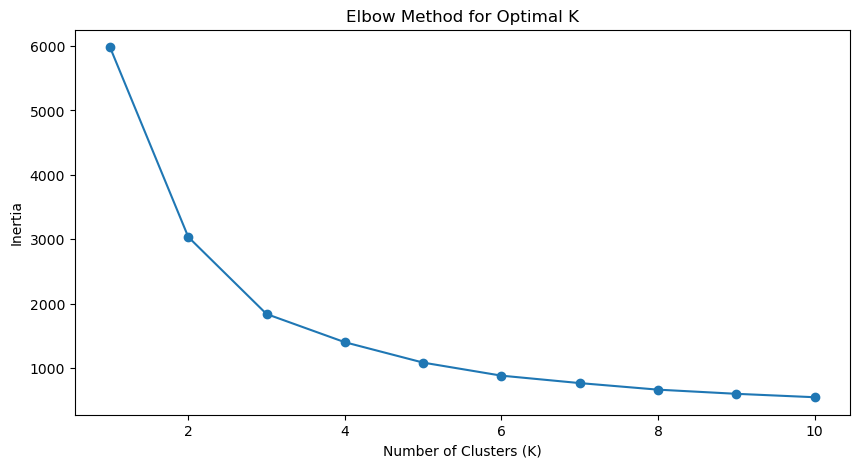

In [21]:
# Elbow method - find optimal K
from sklearn.cluster import KMeans

inertia = []
K_range = range(1, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(rfm_scaled)
    inertia.append(kmeans.inertia_)

plt.figure(figsize=(10, 5))
plt.plot(K_range, inertia, marker='o')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')
plt.title('Elbow Method for Optimal K')
plt.show()

In [22]:
optimal_k = 4

kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
rfm['Cluster'] = kmeans.fit_predict(rfm_scaled)

rfm.head()

,Recency,Frequency,Monetary,Cluster
CustomerName,,,,
Customer 0001,102,14,1300528.40,2
Customer 0002,660,2,308193.76,0
Customer 0003,53,9,1107178.60,3
Customer 0004,38,13,974845.03,2
Customer 0005,115,5,643058.04,3


Even from this small preview, distinct patterns are emerging across the four clusters. Cluster 2 (Customer 0001, 0004) shows low Recency (38-102 days) paired with high Frequency (13-14 orders) and high Monetary value (₦974k-1.3M), these look like the company's most steady customers. Cluster 0 (Customer 0002) stands out with a very high Recency of 660 days, only 2 orders, and the lowest Monetary value (₦308k), this customer likely hasn't purchased in a long time and may be at risk of churn or already lost. Cluster 3 (Customer 0003, 0005) sits in between a moderate Recency (53-115 days), moderate-to-low Frequency (5-9 orders), and mid-to-high Monetary values (₦643k-1.1M) suggesting a steady but not top-tier customers.

This early pattern suggests K-Means is successfully separating customers along the RFM dimensions rather than grouping them, which is a good sign that K=4 was a reasonable choice

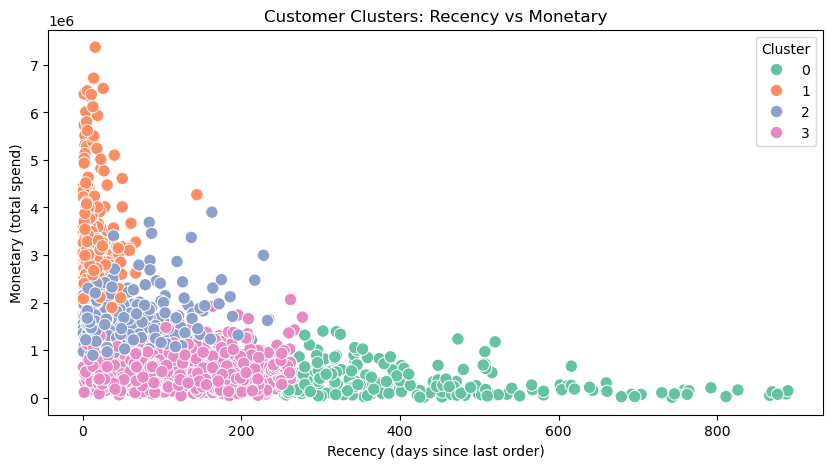

In [23]:
# Combination 1: Recency vs Monetary
plt.figure(figsize=(10, 5))
sns.scatterplot(data=rfm, x='Recency', y='Monetary', hue='Cluster', palette='Set2', s=80)
plt.title('Customer Clusters: Recency vs Monetary')
plt.xlabel('Recency (days since last order)')
plt.ylabel('Monetary (total spend)')
plt.show()

The Recency vs Monetary scatter plot shows strong, visually distinct separation between clusters which is a good sign that K=4 captures real structure in the data rather than forcing arbitrary groupings.

Cluster 1 (orange) sits almost at low Recency (0-150 days) with the highest Monetary values (up to ₦7M+), these are the company's best,
most recently active high-spenders.

Cluster 2 (blue) occupies a similar low-Recency range but with low mid-range Monetary values (roughly ₦1.5-4M), this shows solid, engaged customers who spend less than Cluster 1.

Cluster 3 (purple) clusters at low Recency but low Monetary value (under ₦2M). These customers order recently but spend little per visit, possibly newer or low-value shoppers.

Cluster 0 (teal) is the clearest outlier group: high Recency (200 -800+ days) and consistently low Monetary value. These are customers who haven't purchased in a long time and spend little when they do, making them the strongest churn/at-risk signal in the dataset.

The main axis driving separation here is Recency. Cluster 0 splits off sharply past ~250 days, while Clusters 1, 2, and 3 overlap somewhat with each other at low Recency and differ mainly by Monetary value. This suggests Monetary is doing the heavy lifting to distinguish the "still active" segments from one another, while Recency alone isolates the "gone quiet" group.

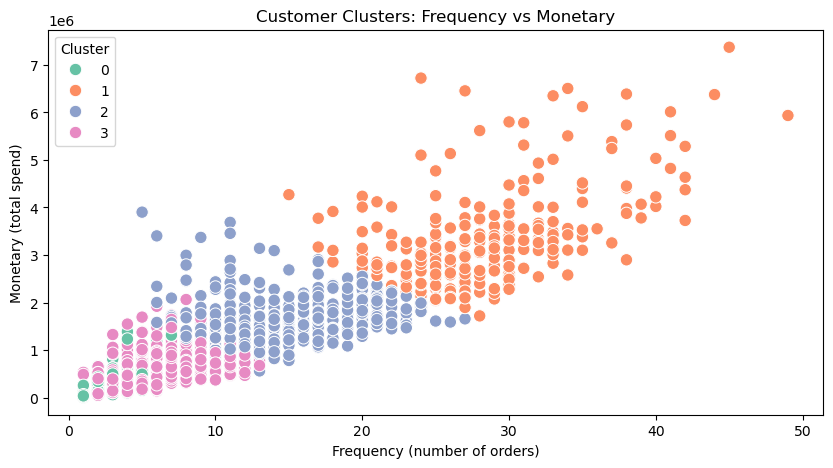

In [24]:
# Combination : Frequency vs Monetary
plt.figure(figsize=(10, 5))
sns.scatterplot(data=rfm, x='Frequency', y='Monetary', hue='Cluster', palette='Set2', s=80)
plt.title('Customer Clusters: Frequency vs Monetary')
plt.xlabel('Frequency (number of orders)')
plt.ylabel('Monetary (total spend)')
plt.show()

The Frequency vs Monetary plot shows a clear, near-linear relationship, as Frequency (number of orders) increases, Monetary (total spend) rises with it, and the four clusters form clean, ordered bands along this diagonal rather than random scatter.

Cluster 3 (purple) occupies the bottom-left: low Frequency (0-13 orders) and low Monetary (under ₦2M), these are infrequent, low-spending customers.

Cluster 2 (blue) sits just above and to the right: Frequency roughly 5-25 orders and Monetary up to ₦4M, these are moderate, steady spenders.

Cluster 1 (orange) dominates the upper-right: Frequency from ~15 up to 50 orders and Monetary reaching ₦7M+, these are the highest-frequency, highest-spending customers.

Cluster 0 (teal), the group identified as at-risk/inactive in Recency plot, appears only as a handful of points at the very bottom-left here (near 0 orders, near ₦0 spend), confirming these are customers who ordered rarely and spent little even when they did.

Unlike the Recency plot, this view shows Frequency and monetary working together almost perfectly to rank customers from low to high value, with far less overlap between clusters than the Recency vs Monetary plot showed. This suggests Frequency and Monetary are the primary drivers separating Clusters 1, 2, and 3 from each other, while Recency is what isolates Cluster 0 as the distinct "inactive" segment.

In [25]:
cluster_profile = rfm.groupby('Cluster')[['Recency', 'Frequency', 'Monetary']].mean().round(2)

# Add customer count per cluster - useful context for sizing each segment
cluster_profile['CustomerCount'] = rfm.groupby('Cluster').size()

cluster_profile

,Recency,Frequency,Monetary,CustomerCount
Cluster,,,,
0,415.37,3.50,335391.06,209
1,14.95,28.55,3368656.20,256
2,47.90,14.09,1524016.11,532
3,108.87,6.49,598433.57,997


In [26]:
segment_labels = {
    0: 'At-Risk / Churned',
    1: 'Champions / High-Value Loyal', 
    2: 'Steady / Regular Customers',
    3: 'New / Low-Engagement'
}

cluster_profile['Segment'] = cluster_profile.index.map (segment_labels)
cluster_profile

,Recency,Frequency,Monetary,CustomerCount,Segment
Cluster,,,,,
0,415.37,3.50,335391.06,209,At-Risk / Churned
1,14.95,28.55,3368656.20,256,Champions / High-Value Loyal
2,47.90,14.09,1524016.11,532,Steady / Regular Customers
3,108.87,6.49,598433.57,997,New / Low-Engagement


Cluster 0 - At-Risk/Churned (209 customers): Hasn't ordered in over a year on average (415 days), with very few lifetime orders (3.5) and lowest total spend of any active-looking segment. These customers have effectively gone quiet and need a win-back campaign before they're lost for good.

Cluster 1 - Champions (256 customers): Ordered within the last 2 weeks on average, with by far the highest order frequency (28.5) and total spend (₦3.37M). This is the company's smallest but most valuable segment and should be top priority for retention and loyalty rewards.

Cluster 2 - Steady Customers (532 customers): Recent activity (48 days), moderate frequency (14 orders), and solid mid-range spend (₦1.52M). These are reliable, engaged customers with clear potential to be upsold into Cluster 1 behavior.

Cluster 3 - New / Low-Engagement (997 customers): The largest segment by far, nearly half the customer base. Fairly recent activity (109 days) but low frequency (6.5 orders) and the second-lowest spend (₦598k). Likely a mix of newer customers still building habits and casual one-off shoppers.

In [27]:
# Applying segment labels to rfm dataframe
rfm['Segment'] = rfm['Cluster'].map(segment_labels)
rfm.head()

,Recency,Frequency,Monetary,Cluster,Segment
CustomerName,,,,,
Customer 0001,102,14,1300528.40,2,Steady / Regular Customers
Customer 0002,660,2,308193.76,0,At-Risk / Churned
Customer 0003,53,9,1107178.60,3,New / Low-Engagement
Customer 0004,38,13,974845.03,2,Steady / Regular Customers
Customer 0005,115,5,643058.04,3,New / Low-Engagement


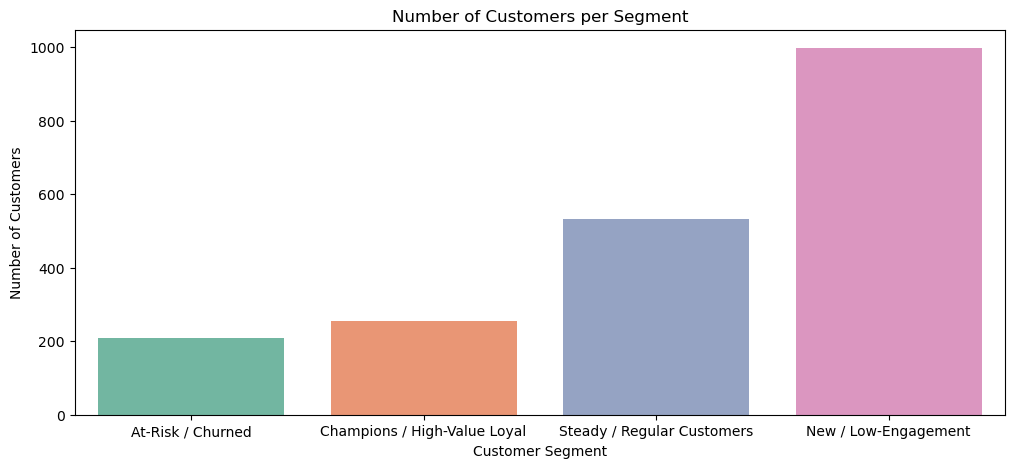

In [28]:
plt.figure(figsize=(12, 5))
sns.barplot(x=cluster_profile['Segment'], y=cluster_profile['CustomerCount'], hue=cluster_profile['Segment'], palette='Set2')
plt.title('Number of Customers per Segment')
plt.xlabel('Customer Segment')
plt.ylabel('Number of Customers')
plt.show()

The New/Low-Engagement segment is nearly twice the size of the next largest group (Steady/Regular Customers) and about 4x the size of the Champions segment, confirming that almost half the customer base has yet to become deeply engaged. This is the single largest opportunity area, even a modest lift in this segment's purchase frequency could outweigh gains from further optimizing the already-small, already-loyal Champions group.

#### Insights & Recommendations

Champions (256 customers) → Action: Protect this segment with a loyalty/VIP program, with early access to new products, exclusive discounts, or a referral incentive. They're the smallest group but drive disproportionate revenue, so the priority here is retention, not acquisition spend.

Steady/Regular (532 customers) → Action: Target with upsell/cross-sell campaigns (bundle offers, "customers like you also bought") to nudge them toward Champions-level frequency. This is the most efficient segment to invest marketing spend in, since they're already engaged and just need a nudge to buy more often.

New/Low-Engagement (997 customers) → Action: Run onboarding/nurture campaigns like welcome series, product education content, or a second-purchase discount to build habit and move them toward the Steady segment. Given this is the largest segment by far, even a small conversion rate improvement here has the biggest total revenue impact of any group.

At-Risk/Churned (209 customers) → Action: Send a win-back campaign, such as a "we miss you" offeror a reactivation discount, before they're lost for good.